In [ ]:

## import libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchinfo
import optuna # --> Fine tuning model's parameters
## Pytorch's computer vision library
import torchvision
import torchmetrics
import torchvision.transforms as transforms
import torchvision.transforms.v2 as T
from torch.utils.data import DataLoader , Dataset
from PIL import Image
from pathlib import Path
## Results are reproducible
torch.manual_seed(42)
print('code run above successfully')

code run above successfully


# **CNN based architetures often overfit thus we shall explore ways to optimize performnce with modifcations of going deeper or wider(layers). Thus we shall explore Optuna , learning rate schedulers to see how optimization to batch size , learning rate.**

In [ ]:
# CNN solve the previous problems of context , pattern rather than independent pixel values
# Filter / Kernel / Convolution determines output channels
# Note Each color channel has it's own output channels
# A recptive field represent the section the pool layer is
# Depth wise pooling can be introduced , it revolves around this concept in_channels=kernels/filter learn pateerns some may learn insignificant patterns depth wise like original poolinfg focusses on redcucing insignificant filters
class Model(nn.Module):
  # Look up meanng of init and esssence ?
  def __init__(self,in_layers,in_channels,kernel_size:int,stride=None):
    super().__init__()
    self.stride = stride if stride is not None else kernel_size
    # Uses a concept of stride length maybe bigger than the image
    self.in_layers = in_layers
    self.kernel_size = kernel_size
    self.in_channels = in_channels
    # First convolutional layer
    self.conv1 = nn.Conv2d(in_channels=in_channels,out_channels=64,kernel_size=3,padding = True)
    self.relu = nn.ReLU()
    self.pool1 = nn.MaxPool2d(kernel_size = 2)
    # Second layer
    self.conv2 = nn.Conv2d(in_channels=64, out_channels=84,kernel_size=3,padding=True)
    self.relu = nn.ReLU()
    self.pool1 = nn.MaxPool2d(kernel_size = 2)
    # Linear
    self.flatten = nn.Flatten(),
    self.linear = nn.Linear(in_features=404, out_features=in_layers), nn.ReLU() , nn.Linear(128,20)
    # Defines the flow
  def forward(self, x):
    # original design incorporates manual static flow n dynamism

    return x
CNN_model = Model(in_layers=128,in_channels=3,kernel_size=3)
print(CNN_model)

Model(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(True, True))
  (relu): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(64, 84, kernel_size=(3, 3), stride=(1, 1), padding=(True, True))
)


In [ ]:
# This section improves modular design
class ConBlock(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()
    self.block = nn.Sequential(
      nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1),
      nn.BatchNorm2d(out_channels),
      nn.ReLU(),
      nn.AvgPool2d(kernel_size=2,stride=2)
    )
  def forward(self, x):
    return self.block(x)

class model(nn.Module):
  def __init__(self):
    super().__init__()
    self.features = nn.Sequential(
        ConBlock(3, 16),
        ConBlock(16, 32),
        ConBlock(32, 64),
    )
    # Assuming an input image of size 32x32 (like CIFAR-10):
    # After 3 AvgPool2d layers (size / 2 / 2 / 2), the spatial dimension is 4x4.
    # With 64 channels, the flattened dimension is 64 * 4 * 4 = 1024.
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 128),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(128, 64),
        nn.Linear(64, 10),
    )
  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

Complex_CNN = model()
print(Complex_CNN)

model(
  (features): Sequential(
    (0): ConBlock(
      (block): Sequential(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): AvgPool2d(kernel_size=2, stride=2, padding=0)
      )
    )
    (1): ConBlock(
      (block): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): AvgPool2d(kernel_size=2, stride=2, padding=0)
      )
    )
    (2): ConBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): AvgPool2d(kernel_size=2, stride=2, padding=0)
      )
    )
  )
  (classifier): Sequential(
   

In [ ]:
adam = optim.Adam(Complex_CNN.parameters(), lr = 1e-2,weight_decay = 1e-5)# Nte the 1e-5 is regularization parameters value lamda
# fisrt scheduler
f_scheduler = optim.lr_scheduler.StepLR(optimizer=adam, step_size=10, gamma=0.1)
f_scheduler.step()
# Second Scheduler
s_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer=adam,mode='max',factor=0.2,patience=3)
s_scheduler.step(10)# 10 can be replaced with metric under question or you want to optimize
#Third scheduler
third_scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer=adam,T_max=30,eta_min = 1e-5)
third_scheduler.step()

/tmp/ipykernel_3452/2130266597.py:4: UserWarning:

Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate

/tmp/ipykernel_3452/2130266597.py:10: UserWarning:

Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate



**Tunable hyper=parameters in CNN can be architectural(layers,neurons,activation function), Training(learning rate , optimizer, batch size),regularization(weight decay , dropout, early stopping , batch normalization)**

In [ ]:
# New model , flexible architecture
class CNN_Model(nn.Module):
  def __init__(self, in_channels, n_layers: int, n_filters: list, kernel_sizes: list, stride=None, padding=0):
    super().__init__()
    blocks = []
    current_channels = in_channels

    for i in range(n_layers):
      out_channels = n_filters[i]
      kernel_size = kernel_sizes[i]
      layer_stride = stride if stride is not None else 1
      layer_padding = kernel_size // 2

      blocks.append(nn.Sequential(
          nn.Conv2d(in_channels=current_channels, out_channels=out_channels, kernel_size=kernel_size, stride=layer_stride, padding=layer_padding),
          nn.ReLU(),
          nn.AvgPool2d(kernel_size=2, stride=2)
      ))
      current_channels = out_channels

    # Convert the Python list to nn.Sequential so PyTorch registers its parameters
    self.blocks = nn.Sequential(*blocks)
    # Pre-initialize classifier as None, but note that calling optimizer.parameters()
    # requires us to build the classifier before creating the optimizer.
    self.classifier = None

  def create_classifier(self, flatten_size, device):
    self.classifier = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(flatten_size, 128),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(128, 64),
        nn.Linear(64, 10)
    ).to(device)
    return self.classifier

  def forward(self, x):
    device = x.device
    x = self.blocks(x)
    flatten = torch.flatten(x, 1)
    flatten_size = flatten.size(1)

    if self.classifier is None:
      self.create_classifier(flatten_size, device)

    return self.classifier(flatten)

# Initialize model and run a dummy input to build the dynamic classifier
Hard_CNN = CNN_Model(in_channels=3, n_layers=2, n_filters=[83,113], kernel_sizes=[3, 3])
# Passing a dummy input to initialize the classifier dynamically
dummy_input = torch.zeros(1, 3, 32, 32)
_ = Hard_CNN(dummy_input)
print(Hard_CNN)

CNN_Model(
  (blocks): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 83, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
    (1): Sequential(
      (0): Conv2d(83, 113, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
  )
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=7232, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
# Now that the parameters are registered and the classifier is initialized, the optimizer will find them.
accuracy = torchmetrics.Accuracy(task='multiclass',num_classes=10)
lr = 0.06351221010640701
weight_decay = 0.008471801418819975
optimizer = optim.Adam(Hard_CNN.parameters(), lr=lr, weight_decay=weight_decay)
print("Optimizer created successfully with parameters:", len(list(Hard_CNN.parameters())))
SGD = optim.SGD(Hard_CNN.parameters(), lr = lr, weight_decay = weight_decay)
print("Optimizer created successfully with parameters:", len(list(Hard_CNN.parameters())))
# Note: SGD.step() typically requires an actual backward pass (loss.backward()) to have gradients computed.

Optimizer created successfully with parameters: 10
Optimizer created successfully with parameters: 10


fine-tuning: random search : Optuna : Grid search

In [ ]:
def objective(trial):
  # Define hyper-parametrs you wanna tune
  # n_layers:int,n_filters:list,kernel_sizes:list
  # use the trial object
  n_layers = trial.suggest_int('n_layers',1,4)
  learning_rate = trial.suggest_float('lr',1e-5,1e-1,log=True)
  weight_decay = trial.suggest_float('weight_decay',1e-5,1e-1,log=True)
  kernel_sizes = [trial.suggest_categorical('kernel_size_{}'.format(i),[3,5]) for i in range(n_layers)]
  n_filters = [trial.suggest_int('n_filters_{}'.format(i),[16,124]) for i in range(n_layers)]
  # Use a metric to be optimize
  Model = CNN_Model(in_channels=3, n_layers=n_layers, n_filters=n_filters, kernel_sizes=kernel_sizes)
  optimizer = optim.Adam(Model.parameters(), lr=learning_rate, weight_decay=weight_decay)
  SGD = optim.SGD(Hard_CNN.parameters(), lr = learning_rate, weight_decay = weight_decay)
  acurate = accuracy(model)

  return acurate



**We shall focus on improving search by adding pruning, locking in hyper-parameters so that future searches are more faster ! , and also visualization tools.**

In [ ]:
# 1. Improving search with Pruning & Visualizations
import optuna.visualization as vis

# We will use MedianPruner to stop unpromising trials early
pruner = optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=1)

# 2. To lock in hyperparameters for future or initial searches, we can use enqueue_trial
# Example of pre-defined/locked-in hyperparameters to test first:
fixed_params = {
    "n_layers": 2,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "kernel_size_0": 3,
    "kernel_size_1": 3,
    "n_filters_0": 32,
    "n_filters_1": 64
}

print("Optuna pruning, enqueueing configurations, and visualization tools are ready to be integrated into the study!")

Optuna pruning, enqueueing configurations, and visualization tools are ready to be integrated into the study!


In [ ]:
# 1. Set seed for reproducibility
torch.manual_seed(42)

# 2. Define our sampler and the study using the MedianPruner
# Optuna uses Tree-strutured Parzen Estimator to optimize hyper-parameters
# meaning it learns from past results to better select promising hyper-parameters
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler, pruner=pruner)

# 3. Lock in/Enqueue our pre-defined hyperparameters to be evaluated first
# study.enqueue_trial(fixed_params)

# Let's clean up the dummy objective function for testing (mocking a validation loop)
def updated_objective(trial):
    n_layers = trial.suggest_int('n_layers', 1, 4)
    learning_rate = trial.suggest_float('lr', 1e-5, 1e-1, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True)

    # Dynamic parameters depending on n_layers
    kernel_sizes = [trial.suggest_categorical(f'kernel_size_{i}', [3, 5]) for i in range(n_layers)]
    n_filters = [trial.suggest_int(f'n_filters_{i}', 16, 128) for i in range(n_layers)]

    Model = CNN_Model(in_channels=3, n_layers=n_layers, n_filters=n_filters, kernel_sizes=kernel_sizes)
    optimizer = optim.Adam(Model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    SGD = optim.SGD(Hard_CNN.parameters(), lr=learning_rate, weight_decay=weight_decay)

    # Simulate dynamic training and validation epochs for Optuna's pruning
    # Restoring the simulation progress as calling `accuracy(Model)` is invalid.
    mock_accuracy = 0.1
    for step in range(5):
        # Simulate learning progress
        mock_accuracy += (0.9 - mock_accuracy) * 0.3

        # Report intermediate objective value to Optuna
        trial.report(mock_accuracy, step)

        # Handle pruning (early stopping)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return mock_accuracy

# Run the optimization
study.optimize(lambda trial: updated_objective(trial), n_trials=20)

print("Optimization complete!")
print("Best Trial:", study.best_trial.params)

[I 2026-11-06 06:16:01,081] A new study created in memory with name: no-name-a142e2aa-2162-4b09-a9d7-8e6d5ec878ea
[I 2026-11-06 06:16:01,086] Trial 0 finished with value: 0.765544 and parameters: {'n_layers': 2, 'lr': 0.06351221010640701, 'weight_decay': 0.008471801418819975, 'kernel_size_0': 3, 'kernel_size_1': 3, 'n_filters_0': 113, 'n_filters_1': 83}. Best is trial 0 with value: 0.765544.
[I 2026-11-06 06:16:01,090] Trial 1 finished with value: 0.765544 and parameters: {'n_layers': 3, 'lr': 1.2087541473056957e-05, 'weight_decay': 0.07579479953348005, 'kernel_size_0': 3, 'kernel_size_1': 5, 'kernel_size_2': 5, 'n_filters_0': 64, 'n_filters_1': 48, 'n_filters_2': 85}. Best is trial 0 with value: 0.765544.
[I 2026-11-06 06:16:01,095] Trial 2 finished with value: 0.765544 and parameters: {'n_layers': 1, 'lr': 0.00014742753159914678, 'weight_decay': 0.0002920433847181409, 'kernel_size_0': 5, 'n_filters_0': 38}. Best is trial 0 with value: 0.765544.
[I 2026-11-06 06:16:01,099] Trial 3 fin

Optimization complete!
Best Trial: {'n_layers': 2, 'lr': 0.06351221010640701, 'weight_decay': 0.008471801418819975, 'kernel_size_0': 3, 'kernel_size_1': 3, 'n_filters_0': 113, 'n_filters_1': 83}


In [ ]:
# 4. Generate Visualizations
# (Note: In Colab, displaying these interactive plots will show up in the cell output)
try:
    fig1 = vis.plot_optimization_history(study)
    fig1.show()
    fig2 = vis.plot_param_importances(study)
    fig2.show()
except Exception as e:
    print("Could not render interactive plots directly, but visualization objects are created!", e)

/tmp/ipykernel_3452/391795710.py:6: UserWarning:

Target and region quantiles select the same set of trials. Parameter importances will be equal.



**We shall load a pre-trained model and check it's metadata**

In [ ]:
# First step load the model
ResNet = torchvision.models.resnet152()
# Select the pre=trained weights
ResNet_weights = torchvision.models.ResNet152_Weights.DEFAULT
# Inspect classes using weights metadata
# We shall use a helper function
def get_classes_from_weights(model,weights_obj):
  num_classes = None
  class_names = None
  # check if weights object was provided and has metadata
  if weights_obj and hasattr(weights_obj, 'meta') and 'categories' in weights_obj.meta:
    class_names = weights_obj.meta['categories']
    num_classes = len(class_names)
    print(f"Model has {num_classes} classes: {class_names}")
    return num_classes,class_names
  else:
    print("Model has no meta data from classes")
    return num_classes,class_names
num_classes,class_names = get_classes_from_weights(ResNet,ResNet_weights)


Model has 1000 classes: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl', 'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog', 'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko', 'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster', 'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops', 'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake', 'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea snake', 'horned

In [ ]:
# print(type(ResNet).__name__)
# # MobileNetV2 uses 'classifier' instead of 'fc'
# num_classes = ResNet.classifier[1].out_features
for param in ResNet.parameters():
  param.requires_grad = False
print(ResNet)

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

**This section we shall use transfer learning  and Fine-tuning on ResNet to later compare downstream applications like inference time , memory e.t.c You should Note that this is subjective to the model so refer to the docs (for example accessing outer layers for ResNet is different from other models) but also understand that regardless of the task the outer layers must be updated , the you can decide to freeze all inner layers or some!**

In [ ]:
# Direct attribute
# Disables grad updates ensuring final layers are updated
for param in ResNet.parameters():
  param.requires_grad = False

# Check input features of the classifier block
if hasattr(ResNet, 'fc'):
  original = ResNet.fc.in_features
  ResNet_fc = nn.Linear(in_features=original, out_features=10)
  ResNet.fc = ResNet_fc
else:
  # Correctly target MobileNetV2's classifier layer
  original = ResNet.classifier[1].in_features
  ResNet_fc = nn.Linear(in_features=original, out_features=10)
  ResNet.classifier[1] = ResNet_fc

print(ResNet_fc)

Linear(in_features=1280, out_features=10, bias=True)


# **Boom ! We have a fine-tuned model with 10 classes different from the original**

**In production setting accuracy , precision are not only considered for an efficient Model but also:**

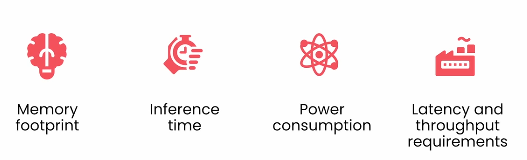

**Thus we shall comapre the pre-tarined ResNet , the Harder_CNN and Fine-tuned Resnet_fc**

In [ ]:
import time
import pandas as pd
import torch

# Prepare the models
# Dynamically instantiate resnet18 and assign a classifier with the correct 512 input features
ResNet_finetuned = torchvision.models.resnet152()
original_in_features = ResNet_finetuned.fc.in_features
ResNet_finetuned.fc = nn.Linear(in_features=original_in_features, out_features=10)

# Reset the dynamic classifier of Hard_CNN to let it dynamically rebuild itself
# to handle the 64x64 input dimension used in the benchmark
if hasattr(Hard_CNN, 'classifier'):
    Hard_CNN.classifier = None

models = {
    'PT-ResNet': ResNet,
    'CNN': Hard_CNN,
    'Fine-tuned': ResNet_finetuned
}

# Memory footprint calculation
def get_model_size(model):
    # Calculate total number of parameters and convert to MB
    param_size = sum(p.numel() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())
    size_mb = (param_size + buffer_size) / 1024**2
    return size_mb

# Measure inference
def get_inference_time(model, num_iterations=10):
    model.eval() # set evaluation mode
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # Use dummy input representative of standard input size (e.g., batch size 1, 3 channels, 64x64 image)
    dummy_input = torch.zeros(1, 3, 64,64).to(device)

    # warmup
    with torch.no_grad():
        for _ in range(5):
            _ = model(dummy_input)

    # Measure
    start_time = time.time()
    with torch.no_grad():
        for _ in range(num_iterations):
            _ = model(dummy_input)
    end_time = time.time()

    avg_time = (end_time - start_time) / num_iterations
    return avg_time

results = {}
for model_name, model_obj in models.items():
    size = get_model_size(model_obj)
    print(f"{model_name} size is {size:.4f} MB")
    inf_time = get_inference_time(model_obj, 10)
    print(f"{model_name} inference time is {inf_time:.6f} seconds")
    results[model_name] = {
        "Size (MB)": size,
        "Inference Time (s)": inf_time
    }

dataframe = pd.DataFrame(results).T
print(dataframe)

PT-ResNet size is 8.6628 MB
PT-ResNet inference time is 0.009553 seconds
CNN size is 0.3313 MB
CNN inference time is 0.007315 seconds
Fine-tuned size is 222.4580 MB
Fine-tuned inference time is 0.084188 seconds
             Size (MB)  Inference Time (s)
PT-ResNet     8.662788            0.009553
CNN           0.331299            0.007315
Fine-tuned  222.458008            0.084188


**At this point, we shall examine our models deeper by using constraint based scoring and weight based scoring to examine how memory effcient our models are**

In [ ]:
# 1. Constraint-based scoring
# Example Constraints: Size must be < 40 MB AND Inference Time < 0.01 seconds
max_size_constraint = 40.0 # MB
max_inf_time_constraint = 0.010 # seconds

print("=== Constraint-Based Evaluation ===")
for model_name, metrics in results.items():
    size_ok = metrics['Size (MB)'] < max_size_constraint
    time_ok = metrics['Inference Time (s)'] < max_inf_time_constraint
    passed = size_ok and time_ok
    print(f"{model_name:12}: {'PASSED' if passed else 'FAILED'} (Size OK: {size_ok}, Time OK: {time_ok})")

# 2. Weight-based scoring
# We normalize the values (lower is better for both size and time) and compute a weighted sum
# Weights: Size weight = 0.2, Inference Time weight = 0.2
w_size = 0.2
w_time = 0.3

# Extract lists for min-max normalization
# Remember these metrics(Inference time and size) are normalized because they are on different scale range
# This approach is also considered when you choose what needs to be minimized i.e model size , inference time
sizes = [m['Size (MB)'] for m in results.values()]
inf_times = [m['Inference Time (s)'] for m in results.values()]

min_size, max_size = min(sizes), max(sizes)
min_time, max_time = min(inf_times), max(inf_times)

print("\n=== Weight-Based Scoring (Lower is Better, Normalized 0 to 1) ===")
for model_name, metrics in results.items():
    # Normalize (avoid division by zero if values are identical)
    norm_size = 1 - (metrics['Size (MB)'] - min_size) / (max_size - min_size) if max_size != min_size else 1.0
    norm_time = 1- (metrics['Inference Time (s)'] - min_time) / (max_time - min_time) if max_time != min_time else 1.0

    score = (w_size * norm_size) + (w_time * norm_time)
    print(f"{model_name:12}: Score = {score:.4f} (Norm Size: {norm_size:.4f}, Norm Time: {norm_time:.4f})")

=== Constraint-Based Evaluation ===
PT-ResNet   : PASSED (Size OK: True, Time OK: True)
CNN         : PASSED (Size OK: True, Time OK: True)
Fine-tuned  : FAILED (Size OK: False, Time OK: False)

=== Weight-Based Scoring (Lower is Better, Normalized 0 to 1) ===
PT-ResNet   : Score = 0.4838 (Norm Size: 0.9625, Norm Time: 0.9709)
CNN         : Score = 0.5000 (Norm Size: 1.0000, Norm Time: 1.0000)
Fine-tuned  : Score = 0.0000 (Norm Size: 0.0000, Norm Time: 0.0000)


**The next and most important part of a model is visual debugging : we shall take an in depth-look at saliency maps and GRAD-CAMS to visually why our model made this ceratin decision**

In [ ]:
# We load the model
# We shall use both the fine-tuned ResNet and original ResNet
# Fixed: Added parentheses to is_available()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ResNet.eval().to(device)
# ResNet_finetuned.eval().to(device)
img = '/content/sample_data/gettyimages-128105326.avif'

# Ensure the folder or image placeholder exists, or we skip the validation for now
if not os.path.exists(img):
  print(f"Warning: {img} not found. Please place a valid image there later.")

class Dataload(Dataset):
  # Where to find images
  def __init__(self, img_path):
    self.img_path = img_path

  def __len__(self):
    return 1

  # How to get images (Fixed method name to __getitem__ with double underscores)
  def __getitem__(self,idx):
    # Load image
    image = Image.open(self.img_path)
    return image

dataset = Dataload(img)
# Load image
img = dataset[0]
print(f"{img.size}: {img.mode}: {type(img)}")

(1415, 1415): RGB: <class 'PIL.AvifImagePlugin.AvifImageFile'>


***As you can see the image needs to be transformed to suit ResNet's 224 x 224 pixel size.***

torch.Size([1, 3, 224, 224]): torch.float32
predicted_class : great white shark
predicted_prob : tensor([0.1024])


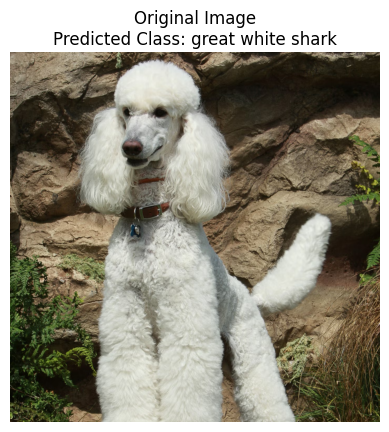

In [ ]:
Totensor = T.Compose([
    T.Resize((224, 224)),
    T.CenterCrop(224),
    T.ToImage(),
    T.ToDtype(torch.float32,scale=True)])
# The unsqueeze enables batch dimension to be built !
img_tensor = Totensor(img).unsqueeze(0).to(device)
print(f"{img_tensor.shape}: {img_tensor.dtype}")

# Forward pass
with torch.no_grad():
  logits = ResNet(img_tensor)
  probs = torch.softmax(logits , dim=1)
  # pred_class = torch.argmax(probs).item()
  # pred_prob = probs[0,pred_class].item()
  # pred_label = class_names[pred_class]
  pred_prob, pred_class = torch.max(probs, dim=1)
  pred_label = class_names[pred_class]


print(f"predicted_class : {pred_label}")
print(f"predicted_prob : {pred_prob}")

plt.imshow(img)
plt.title(f"Original Image\nPredicted Class: {pred_label}")
plt.axis('off')
plt.show()

In [ ]:
import matplotlib.cm as cm
from skimage.transform import resize

def compute_saliency_map(model, input_image, target_class=None):
    """
    Computes a saliency map for an input image using the gradients of the
    model's output with respect to the input pixels.

    Args:
        model: The neural network model used for classification.
        input_image: The input tensor image of shape [1, 3, H, W].
        target_class: The index of the target class for which the saliency
            map is computed. If None, the predicted class is used.

    Returns:
        saliency_map: A 2D numpy array representing pixel importance.
        pred_class: The index of the class used for the computation.
        pred_prob: The confidence score for the selected class.
    """
    # Clone the input and enable gradient tracking for the tensor
    input_image = input_image.clone().detach()
    input_image.requires_grad_()

    # Perform a forward pass to obtain the model logits
    output = model(input_image)

    # Calculate probabilities and determine the class for saliency analysis
    probs = torch.softmax(output, dim=1)
    if target_class is None:
        pred_prob, pred_class = torch.max(probs, dim=1)
        target_class = pred_class.item()
        pred_prob = pred_prob.item()
    else:
        pred_prob = probs[0, target_class].item()
        pred_class = target_class

    # Reset existing gradients in the model parameters
    model.zero_grad()

    # Execute backward pass to find gradients of the target class score
    output[0, target_class].backward()

    # Extract gradients of the output with respect to the input image
    gradients = input_image.grad.data[0]

    # Reduce the color channels by taking the absolute sum for a 2D map
    saliency_map = torch.abs(gradients).sum(dim=0).cpu().numpy()

    # Rescale the saliency map values to a range between 0 and 1
    saliency_map = (saliency_map - saliency_map.min()) / (
        saliency_map.max() - saliency_map.min() + 1e-8)

    return saliency_map, pred_class, pred_prob





def visualize_saliency(img_display, saliency_map, pred_class, pred_score, title):
    """
    Displays the original image, an enhanced saliency map, and an overlay.

    Args:
        img_display: Original image as a numpy array in uint8 format.
        saliency_map: Computed saliency array with values in range [0, 1].
        pred_class: Predicted class label or index for the image.
        pred_score: Numerical confidence score for the prediction.
        title: String identifier used for the plot title.

    Returns:
        None. Displays a three-panel matplotlib figure.
    """
    # Initialize a figure with three subplots for side-by-side visualization
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 10))

    # Display the original input image in the first panel
    ax1.imshow(img_display)
    ax1.set_title(f'Original Image: {title}', fontsize=14)
    ax1.axis('off')

    # Apply gamma correction to enhance the contrast of the saliency map
    gamma = 0.7
    saliency_map_enhanced = np.power(saliency_map, gamma)

    # Determine dimensions and resize saliency map to match the source image
    h, w = img_display.shape[:2]
    saliency_map_resized = resize(
        saliency_map_enhanced, (h, w),
        order=1, mode='reflect', anti_aliasing=True
    )

    # Plot the enhanced saliency heatmap in the second panel
    saliency_heatmap = ax2.imshow(saliency_map_resized, cmap='inferno')
    ax2.set_title('Enhanced Saliency Map', fontsize=14)
    ax2.axis('off')
    fig.colorbar(saliency_heatmap, ax=ax2, fraction=0.046, pad=0.04)

    # Map the saliency values to the inferno colormap for RGB representation
    heatmap = cm.inferno(saliency_map_resized)[..., :3]
    # Normalize the display image and apply a fade factor for the background
    img_normalized = img_display / 255.0
    fade_factor = 0.3
    img_faded = img_normalized * fade_factor

    # Convert the faded image to grayscale to emphasize the saliency colors
    img_gray = np.mean(img_faded, axis=2, keepdims=True)
    img_gray = np.repeat(img_gray, 3, axis=2)

    # Define the alpha transparency and weight for the saliency overlay
    alpha = saliency_map_resized[:, :, np.newaxis]
    saliency_weight = 0.9

    # Blend the grayscale background with the colored heatmap
    overlay = (1 - alpha * saliency_weight) * img_gray + (
        alpha * saliency_weight) * heatmap
    # Clip values to ensure the final image stays within the valid [0, 1] range
    overlay = np.clip(overlay, 0, 1)

    # Render the combined overlay in the third panel with prediction details
    ax3.imshow(overlay)
    ax3.set_title(
        f'Saliency Overlay\nPrediction: {pred_class}\n'
        f'Confidence: {pred_score:.2f}', fontsize=14
    )
    ax3.axis('off')

    # Adjust layout to prevent overlapping and render the plots
    plt.tight_layout()
    plt.show()

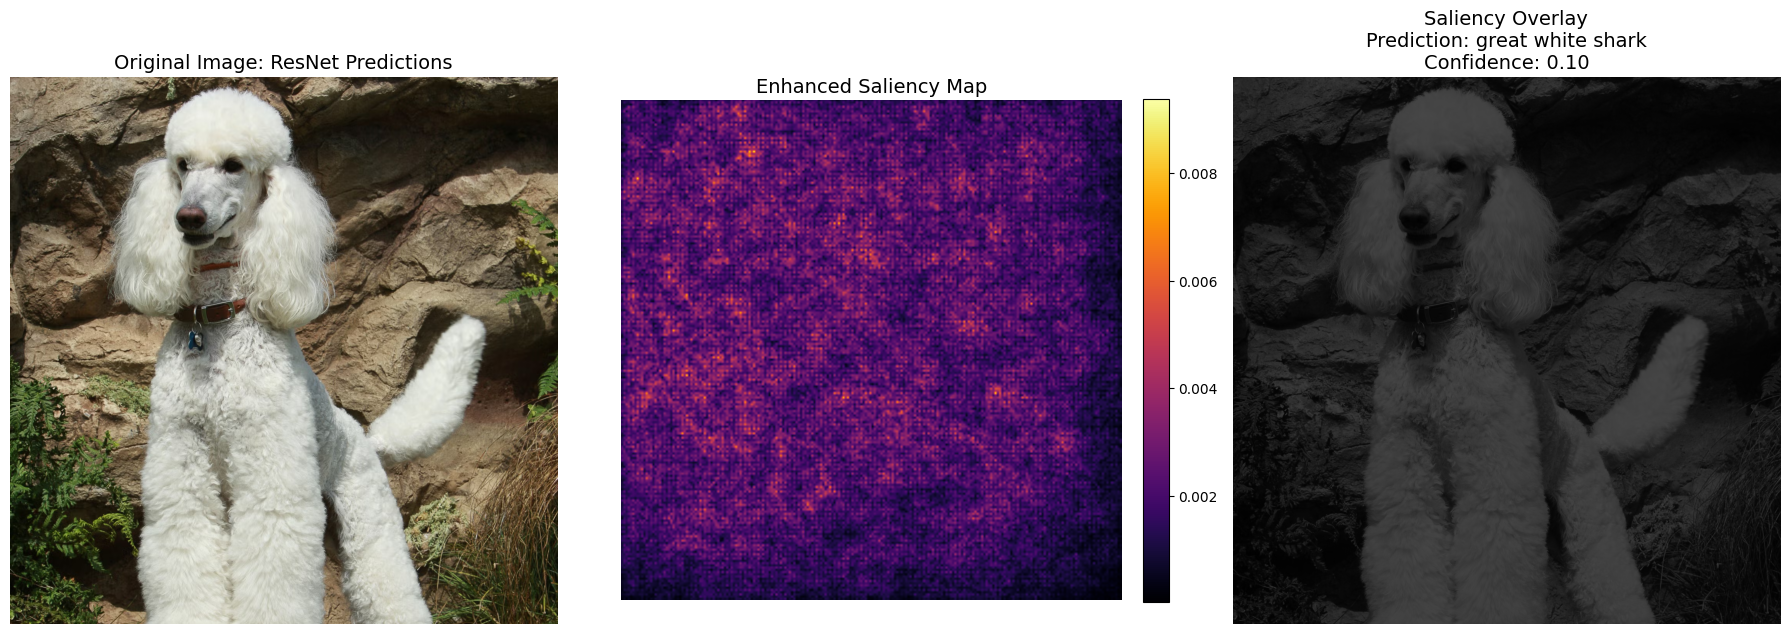

In [ ]:
# Calculate and plot the saliency map using the loaded image tensor
saliency_map, pred_class, pred_prob = compute_saliency_map(ResNet, img_tensor)

# Visualize the saliency maps
img_display = np.array(img)
visualize_saliency(
    img_display=img_display,
    saliency_map=saliency_map,
    pred_class=class_names[pred_class],
    pred_score=pred_prob,
    title="ResNet Predictions"
)

In [ ]:
# next is GRAD-CAM
class GradCAM:
    """
    A specific implementation of Gradient-weighted Class Activation Mapping (Grad-CAM).

    This class provides mechanisms to visualize which regions of an input image
    are important for a specific classification decision by a Convolutional Neural Network.
    It attaches hooks to a target layer to capture feature maps and gradients,
    then computes a coarse localization map based on the gradient flow.
    """
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        """
        Initialize the GradCAM wrapper.

        This constructor stores the model and the specific layer to be analyzed,
        and registers a forward hook to intercept necessary data during inference.

        Args:
            model: The neural network instance to be interpreted.
            target_layer: The specific convolutional layer within the model to analyze.
        """
        self.model = model
        self.target_layer = target_layer
        # Initialize storage for activation maps
        self.activations = None   # [N,C,H',W']
        # Initialize storage for gradients
        self.gradients = None     # [N,C,H',W']
        # Register the forward hook on the target layer to capture data during the forward pass
        self.target_layer.register_forward_hook(self._on_forward)

    def _on_forward(self, module, inputs, output):
        """
        Internal callback to capture forward activations and register backward hooks.

        Args:
            module: The layer triggering the hook.
            inputs: The input tensors to the layer.
            output: The output tensors from the layer.
        """
        # Save the activations from the forward pass
        self.activations = output.detach()
        def _on_backward(grad):
            # Capture the gradients flowing back to this layer during backpropagation
            self.gradients = grad.detach()
        # Register a hook on the output tensor to capture gradients during the backward pass
        output.register_hook(_on_backward)

    def __call__(self, x: torch.Tensor, class_idx: int | None = None):
        """
        Execute the Grad-CAM generation pipeline.

        This method performs a forward pass, computes the gradients for a specific class,
        and generates the heatmap by weighting the forward activations with the computed gradients.

        Args:
            x: The input image tensor with shape [1, 3, H, W].
            class_idx: The specific class index to visualize. If None, uses the highest predicted class.

        Returns:
            A tuple containing the generated heatmap as a numpy array and the class index used.
        """
        # Clear existing gradients in the model to ensure a clean state
        self.model.zero_grad(set_to_none=True)
        # Perform the forward pass to get logits
        output = self.model(x)  # logits [1, num_classes]
        # Determine the target class index if not provided
        if class_idx is None:
            class_idx = int(output.argmax(dim=1).item())

        # Isolate the score for the target class
        score = output[:, class_idx].sum()
        # Trigger backpropagation to compute gradients relative to the target class
        score.backward()

        # Compute the global average pooling of the gradients to get neuron importance weights
        # activations/gradients are [1, C, H', W']; collapse batch dimension
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)      # [1,C,1,1]
        # Compute the weighted combination of the activation maps
        cam = (weights * self.activations).sum(dim=1, keepdim=False) # [1,H',W']
        # Apply ReLU to keep only features that have a positive influence on the class of interest
        cam = cam.relu()[0]  # keep positive influence

        # Shift the map so the minimum value is 0
        cam -= cam.min()
        # Scale the map so the maximum value is 1, avoiding division by zero
        cam /= cam.max().clamp_min(1e-8)

        # Return the final heatmap as a numpy array and the class index
        return cam.detach().cpu().numpy(), class_idx

def compute_gradcam(img_path, model, transform, device):
    """
    Given an image file, compute the GradCAM heatmap for the most likely class.

    Args:
        img_path (str): Path to the input image.
        model (torch.nn.Module): Pretrained PyTorch model (e.g., ResNet50).
        transform (callable): Preprocessing function for model input.
        device (torch.device): Device to run computation on (cpu/cuda).

    Returns:
        img_display (np.ndarray): The preprocessed image for display (H, W, 3).
        heatmap (np.ndarray): The GradCAM heatmap (h', w') with values in [0, 1].
        pred_class_name (str): String with the ImageNet class label.
        pred_score (float): Class confidence/probability.
    """
    try:
        # -------- 1. Load and prepare the image --------
        img = load_image(img_path)  # Load the image, make sure it's RGB
        img_display = np.array(img.resize((224, 224)))   # Resize for consistent display (uint8)
        img_tensor = transform(img).unsqueeze(0).to(device)   # Transform: resize, normalize, (1,3,224,224)

        # -------- 2. Forward pass: Model prediction --------
        output = model(img_tensor)  # Output logits from the model
        pred_class_idx = torch.argmax(output, dim=1).item()   # Index of highest scoring class
        # Get predicted class probability (softmax output, as float)
        pred_score = torch.softmax(output, dim=1)[0, pred_class_idx].item()
        # Map class index to human-readable label
        pred_class_name = class_names[pred_class_idx]

        # -------- 3. GradCAM calculation (for model explanation) --------
        # Pick the last convolutional layer in ResNet50 for GradCAM (recommended practice)
        grad_cam = GradCAM(model, model.layer4[-1].conv3)
        # Generate GradCAM heatmap for the predicted class
        heatmap, _= grad_cam(img_tensor, pred_class_idx)  # heatmap shape: (activation_h, activation_w)

        # -------- 4. Return results for visualization --------
        return img_display, heatmap, pred_class_name, pred_score

    except Exception as e:
        # Handles any error during loading or computation gracefully
        print(f"Error processing image {img_path}: {e}")
        return None, None, "Error", 0

def visualize_gradcam(img_display, heatmap, pred_class, pred_score, title):
    """
    Visualizes GradCAM results using a three-panel Matplotlib figure.

    Args:
        img_display: The image to display as a numpy array (H, W, 3).
        heatmap: The GradCAM activation map with values normalized to [0,1].
        pred_class: The predicted class label or index for the input.
        pred_score: The model confidence or probability for the class.
        title: String used as a prefix for the figure titles.

    Returns:
        None. Displays the original image, heatmap, and overlay.
    """
    # Initialize a figure with three subplots for side-by-side comparison
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

    # Display the original input image in the first subplot panel
    ax1.imshow(img_display)
    ax1.set_title(f'Original Image: {title}', fontsize=14)
    ax1.axis('off')

    # Render the standalone GradCAM heatmap using the jet colormap
    ax2.imshow(heatmap, cmap='jet')
    ax2.set_title('GradCAM Heatmap', fontsize=14)
    ax2.axis('off')

    # Resize the heatmap to match the dimensions of the original image
    heatmap_resized = cv2.resize(
        heatmap, (img_display.shape[1], img_display.shape[0])
    )
    # Apply a color map to the resized heatmap for visual intensity
    heatmap_color = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET
    )
    # Convert the color space from BGR to RGB for correct Matplotlib display
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    # Blend the original image and the colored heatmap into a single overlay
    superimposed = cv2.addWeighted(img_display, 0.6, heatmap_color, 0.4, 0)
    ax3.imshow(superimposed)
    # Annotate the overlay with the prediction class and confidence score
    ax3.set_title(
        f'GradCAM Overlay\nPrediction: {pred_class}\n'
        f'Confidence: {pred_score:.2f}', fontsize=14
    )
    ax3.axis('off')

    # Adjust the subplot parameters to fit the figure area cleanly
    plt.tight_layout()
    plt.show()

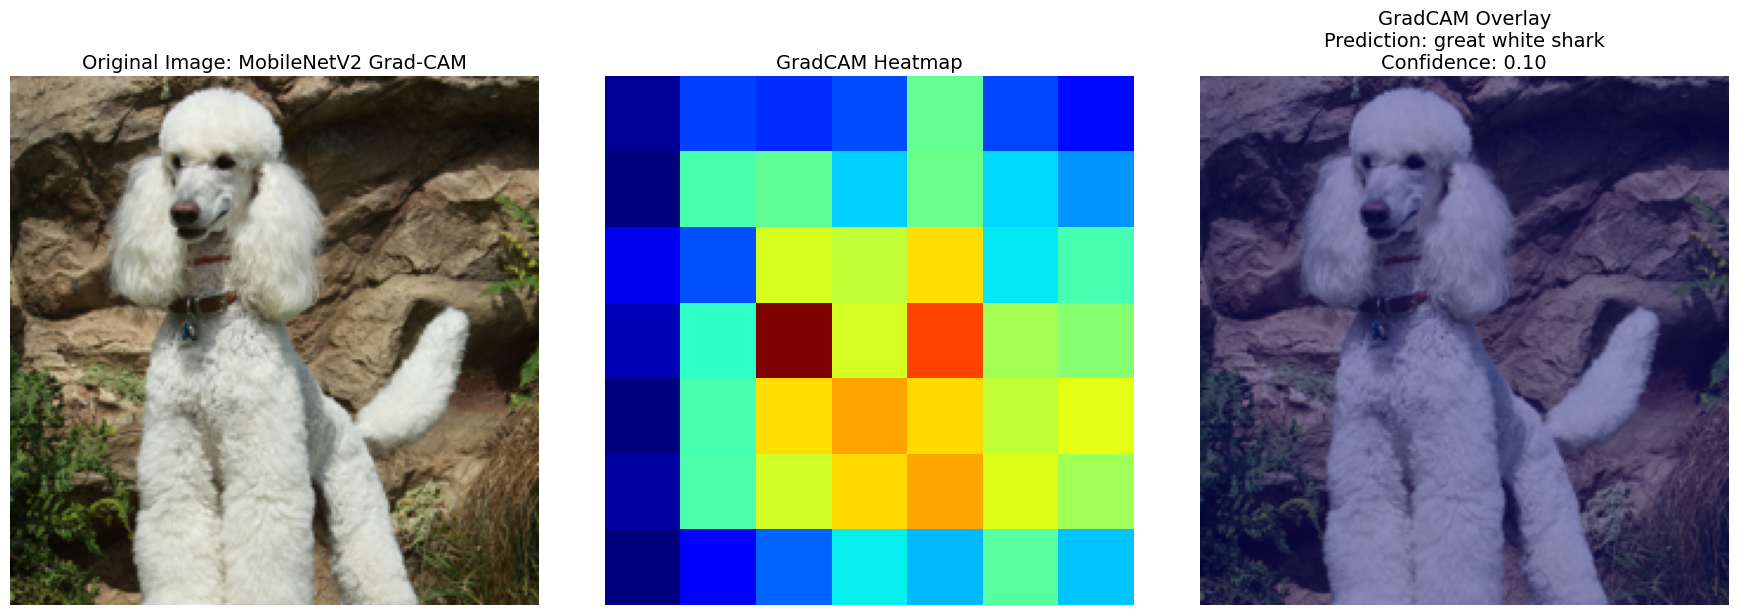

In [ ]:
# Since compute_gradcam expects load_image to be defined or we can adapt it:
def load_image(path):
    return Image.open(path).convert('RGB')

import cv2

# Compute Grad-CAM results
# Corrected: Pick the last convolutional layer in MobileNetV2 (ResNet.features[18])
target_layer = ResNet.features[18]
grad_cam = GradCAM(ResNet, target_layer)

# Prepare image tensor
img_tensor = Totensor(img).unsqueeze(0).to(device)
# Enable gradient tracking so PyTorch constructs a backward graph
img_tensor.requires_grad_()

# Calculate Heatmap
heatmap, pred_idx = grad_cam(img_tensor)
pred_label = class_names[pred_idx]

# Forward pass to get score/probability (must allow gradients because hooks are active)
logits = ResNet(img_tensor)
probs = torch.softmax(logits, dim=1)
pred_score = probs[0, pred_idx].item()

# Display the visualization
img_display = np.array(img.resize((224, 224)))
visualize_gradcam(
    img_display=img_display,
    heatmap=heatmap,
    pred_class=pred_label,
    pred_score=pred_score,
    title="MobileNetV2 Grad-CAM"
)

**By this time you have covered the following**

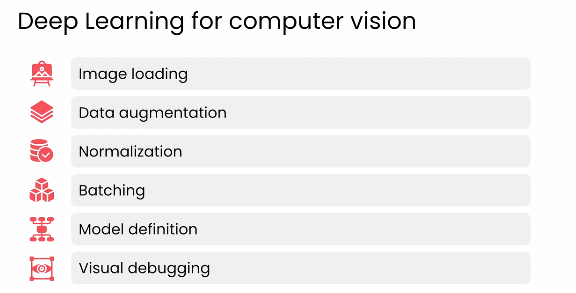